# 11_relabel_any_readmission.ipynb — เปลี่ยน label ตามคำแนะนำอาจารย์ (ขั้นที่ 1 จาก 4)

**สิ่งที่เปลี่ยนจาก `07_final_calibrated_pipeline.ipynb`**

1. **Label ใหม่**: `<30` และ `>30` → 1, `NO` → 0 (สลับกลับเป็นแบบเดิมได้ด้วย `LABEL_MODE = "30d"` เพื่อรายงานเทียบกันในเปเปอร์)
2. **Inner CV ของ stacking เป็น GroupKFold ตาม `patient_nbr`** (รวม patch GroupKFold ไว้ในตัว ไม่ต้อง patch แยก)
3. **แบ่งข้อมูล 3 ส่วนตามผู้ป่วย**: train 64% / validation 16% / test 20%
   - validation ใช้ fit isotonic calibration และ**เลือก threshold** → test ใช้วัดผลอย่างเดียว (แก้ปัญหา threshold selection leakage ที่เคยมีใน 07)
4. **บันทึก split ไว้เป็นไฟล์** (`split_assignment.csv`) ให้ notebook 12 (survival), 13 (LSTM), 14 (feature analysis) ใช้ผู้ป่วยชุดเดียวกัน เทียบผลกันได้ตรงๆ
5. **วัดผลเทียบ baseline เสมอ** เพราะ base rate ใหม่ ~47% ตัวเลข PR-AUC จะดูสูงขึ้นมากโดยอัตโนมัติ ห้ามเอาไปเทียบกับตัวเลขของ label เดิมตรงๆ

Feature engineering และ hyperparameter เหมือน 07 ทุกอย่าง เพื่อให้ความต่างของผลมาจาก label อย่างเดียว

ก่อนรัน: `pip install xgboost` (ถ้าไม่มี notebook จะ fallback ไปใช้ HistGradientBoosting และพิมพ์เตือน — ผลแบบนั้นใช้ทดสอบโค้ดได้ แต่ห้ามใส่เปเปอร์)

## 0. Config

In [1]:
LABEL_MODE = "any"      # "any" = <30 หรือ >30 → 1 (label ใหม่ตามอาจารย์) | "30d" = <30 → 1 (label เดิม)
RANDOM_STATE = 42
COST_FN, COST_FP = 5, 1  # ต้นทุนพลาดเคส : แจ้งเตือนเกิน (ใช้หา cost-optimal threshold)

RAW_PATH = "../data/diabetic_data.csv"   # แก้ path ตามที่เก็บไฟล์จริง
OUT_DIR = f"../outputs/11_{LABEL_MODE}"
MODEL_DIR = "../models"
SPLIT_PATH = "../outputs/split_assignment.csv"  # ใช้ร่วมกับ notebook 12–14

## 1. Imports

In [2]:
import os, json, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.pipeline import Pipeline
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    confusion_matrix, classification_report, brier_score_loss,
)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    HAS_XGB = False
    print("⚠️ ไม่พบ xgboost — ใช้ HistGradientBoosting แทนชั่วคราว ผลที่ได้ห้ามใส่เปเปอร์")

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(os.path.dirname(SPLIT_PATH), exist_ok=True)

## 2. Load, Clean และสร้าง Label

In [3]:
df = pd.read_csv(RAW_PATH, keep_default_na=False, na_values=["?"])
print(f"Raw shape: {df.shape}")

df = df[df["gender"] != "Unknown/Invalid"]
death_hospice_codes = [11, 13, 14, 19, 20, 21]
df = df[~df["discharge_disposition_id"].isin(death_hospice_codes)]

df = df.sort_values(["patient_nbr", "encounter_id"]).reset_index(drop=True)
print(f"Shape after cleaning: {df.shape}")

# เก็บ label ดิบ 3 ช่วงไว้แยก (notebook 12 survival ต้องใช้) แล้วลบออกจาก df ทันทีกัน leakage
meta = df[["encounter_id", "patient_nbr", "readmitted"]].rename(columns={"readmitted": "readmitted_raw"}).copy()

if LABEL_MODE == "any":
    df["readmitted"] = (df["readmitted"] != "NO").astype(int)
elif LABEL_MODE == "30d":
    df["readmitted"] = (df["readmitted"] == "<30").astype(int)
else:
    raise ValueError("LABEL_MODE ต้องเป็น 'any' หรือ '30d'")

print(f"\nLABEL_MODE = {LABEL_MODE}")
print(pd.crosstab(meta["readmitted_raw"], df["readmitted"], margins=True))
print(f"\nBase rate (สัดส่วนคลาส 1): {df['readmitted'].mean():.4f}")

Raw shape: (101766, 50)
Shape after cleaning: (99340, 50)

LABEL_MODE = any
readmitted          0      1    All
readmitted_raw                     
<30                 0  11314  11314
>30                 0  35502  35502
NO              52524      0  52524
All             52524  46816  99340

Base rate (สัดส่วนคลาส 1): 0.4713


## 3. Feature Engineering (เหมือน 07 ทุกบรรทัด)

In [4]:
med_cols = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone",
]
med_cols = [c for c in med_cols if c in df.columns]

df["medication_change_count"] = (df[med_cols] == "Up").sum(axis=1) + (df[med_cols] == "Down").sum(axis=1)
df["num_meds_active"] = (df[med_cols] != "No").sum(axis=1)
df["tested_glucose"] = (df["max_glu_serum"] != "None").astype(int)
df["tested_A1C"] = (df["A1Cresult"] != "None").astype(int)

df["visit_number"] = df.groupby("patient_nbr").cumcount() + 1
df["change_flag"] = (df["change"] == "Ch").astype(int)
df["prior_change_count"] = df.groupby("patient_nbr")["change_flag"].cumsum() - df["change_flag"]
df = df.drop(columns=["change_flag"])

df["total_prior_visits"] = df["number_outpatient"] + df["number_emergency"] + df["number_inpatient"]
df["had_prior_inpatient"] = (df["number_inpatient"] > 0).astype(int)

In [5]:
def map_diagnosis(code):
    if pd.isna(code):
        return "Missing"
    code = str(code)
    if code.startswith("V") or code.startswith("E"):
        return "Other"
    try:
        val = float(code)
    except ValueError:
        return "Other"
    if 390 <= val <= 459 or val == 785:
        return "Circulatory"
    elif 460 <= val <= 519 or val == 786:
        return "Respiratory"
    elif 520 <= val <= 579 or val == 787:
        return "Digestive"
    elif 250 <= val < 251:
        return "Diabetes"
    elif 800 <= val <= 999:
        return "Injury"
    elif 710 <= val <= 739:
        return "Musculoskeletal"
    elif 580 <= val <= 629 or val == 788:
        return "Genitourinary"
    elif 140 <= val <= 239:
        return "Neoplasms"
    else:
        return "Other"

diag_groups = pd.DataFrame({c: df[c].apply(map_diagnosis) for c in ["diag_1", "diag_2", "diag_3"]})
df["comorbidity_count"] = diag_groups.apply(lambda row: row[row != "Missing"].nunique(), axis=1)
for c in ["diag_1", "diag_2", "diag_3"]:
    df[c] = diag_groups[c]

df["age_ord"] = df["age"].map({
    "[0-10)": 5, "[10-20)": 15, "[20-30)": 25, "[30-40)": 35,
    "[40-50)": 45, "[50-60)": 55, "[60-70)": 65, "[70-80)": 75,
    "[80-90)": 85, "[90-100)": 95,
})
df["age_x_medications"] = df["age_ord"] * df["num_medications"]
df["hospital_stay_x_inpatient"] = df["time_in_hospital"] * df["number_inpatient"]

df.drop(columns=["weight", "payer_code", "encounter_id"], inplace=True)

df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
top_specialties = df["medical_specialty"].value_counts().nlargest(10).index
df["medical_specialty"] = df["medical_specialty"].where(df["medical_specialty"].isin(top_specialties), "Other")
df["race"] = df["race"].fillna("Missing")

constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print(f"Dropping constant columns: {constant_cols}")
df.drop(columns=constant_cols, inplace=True)

Dropping constant columns: ['examide', 'citoglipton']


## 4. Encode + แบ่ง Train / Validation / Test ตามผู้ป่วย

GroupShuffleSplit ไม่ได้ใช้ค่า y ในการแบ่ง ดังนั้น `LABEL_MODE` ทั้งสองแบบจะได้**ผู้ป่วยชุดเดียวกันทุกประการ** เทียบผลกันได้ยุติธรรม

In [6]:
TARGET_COL, GROUP_COL = "readmitted", "patient_nbr"

X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]
groups = df[GROUP_COL].values

categorical_cols = [c for c in X.columns if c != GROUP_COL and pd.api.types.is_string_dtype(X[c]) and c != "age"]
X = X.drop(columns=["age"])

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    label_encoders[col] = le

demo_raw = df[["race", "gender", "age"]].copy()

# test 20%
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(gss_test.split(X, y, groups=groups))
# validation = 20% ของส่วนที่เหลือ (= 16% ของทั้งหมด)
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
fit_rel, val_rel = next(gss_val.split(X.iloc[trainval_idx], y.iloc[trainval_idx], groups=groups[trainval_idx]))
fit_idx, val_idx = trainval_idx[fit_rel], trainval_idx[val_rel]

split_label = np.empty(len(df), dtype=object)
split_label[fit_idx], split_label[val_idx], split_label[test_idx] = "train", "val", "test"

def take(idx):
    return X.iloc[idx].drop(columns=[GROUP_COL]).reset_index(drop=True), y.iloc[idx].reset_index(drop=True)

X_fit, y_fit = take(fit_idx)
X_val, y_val = take(val_idx)
X_test, y_test = take(test_idx)
groups_fit = groups[fit_idx]
demo_test = demo_raw.iloc[test_idx].reset_index(drop=True)

sets = {"train": fit_idx, "val": val_idx, "test": test_idx}
for a in sets:
    for b in sets:
        if a < b:
            ov = set(groups[sets[a]]) & set(groups[sets[b]])
            print(f"Patient overlap {a}-{b} (ต้องเป็น 0): {len(ov)}")
for name, idx in sets.items():
    print(f"{name:5s}: n={len(idx):6d}  base rate={y.iloc[idx].mean():.4f}")

# บันทึก split ให้ notebook 12–14 ใช้ร่วมกัน
split_df = meta.assign(split=split_label)
split_df.to_csv(SPLIT_PATH, index=False)
print(f"\nSaved split → {SPLIT_PATH}")

Patient overlap train-val (ต้องเป็น 0): 0
Patient overlap test-train (ต้องเป็น 0): 0
Patient overlap test-val (ต้องเป็น 0): 0
train: n= 63605  base rate=0.4725
val  : n= 15962  base rate=0.4740
test : n= 19773  base rate=0.4651

Saved split → ../outputs/split_assignment.csv


## 5. Base Models + Stacking (inner CV = GroupKFold)

Hyperparameter เดิมจาก `05_improved_pipeline4.ipynb` — ตั้งใจไม่ tune ใหม่ เพื่อให้เทียบ label สองแบบได้โดยตัวแปรอื่นคงที่ (ถ้าจะ tune ใหม่สำหรับ label ใหม่ ให้ทำเป็นการทดลองแยกและรายงานแยก)

`cv` ของ StackingClassifier รับ list ของ (train, test) index ได้ จึงคำนวณ GroupKFold ล่วงหน้าแล้วส่งเข้าไป ทำให้ out-of-fold prediction ที่ meta-learner ใช้เรียนไม่มีผู้ป่วยซ้ำข้าม fold

In [7]:
rf = RandomForestClassifier(
    n_estimators=500, max_depth=8, min_samples_leaf=5,
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
)
if HAS_XGB:
    gb = XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.01, subsample=0.9,
        eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1,
        scale_pos_weight=(y_fit == 0).sum() / (y_fit == 1).sum(),
    )
else:
    gb = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300,
                                        class_weight="balanced", random_state=RANDOM_STATE)

inner_splits = list(GroupKFold(n_splits=5).split(X_fit, y_fit, groups=groups_fit))

stacking_model = StackingClassifier(
    estimators=[("rf", rf), ("xgboost" if HAS_XGB else "hgb", gb)],
    final_estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ]),
    cv=inner_splits, n_jobs=-1, passthrough=True,
)

print("Training stacking ensemble...")
stacking_model.fit(X_fit, y_fit)
print("Done.")

Training stacking ensemble...
Done.


## 6. Isotonic Calibration บน Validation Set

ต่างจาก 07 ที่ใช้ `CalibratedClassifierCV(cv=3)` (ต้อง refit stacking ซ้ำ 3 รอบและ inner CV ไม่ group-aware) — ที่นี่ fit `IsotonicRegression` บน validation ที่แยกผู้ป่วยไว้แล้ว เร็วกว่ามาก และใช้ได้กับ scikit-learn ทุกเวอร์ชัน

Metric (test)          Uncalibrated     Calibrated
PR-AUC                       0.6461         0.6365
ROC-AUC                      0.6814         0.6806
Brier                        0.2245         0.2239


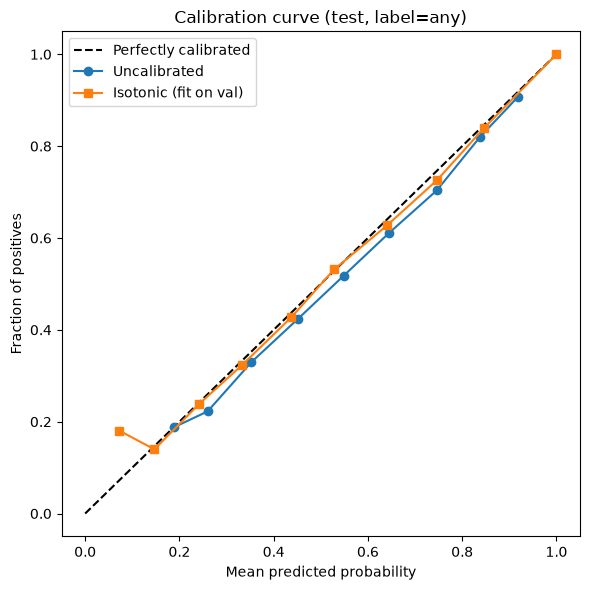

In [8]:
raw_val = stacking_model.predict_proba(X_val)[:, 1]
raw_test = stacking_model.predict_proba(X_test)[:, 1]

iso = IsotonicRegression(out_of_bounds="clip", y_min=0.0, y_max=1.0).fit(raw_val, y_val)
proba_val = iso.predict(raw_val)
proba_test = iso.predict(raw_test)

print(f"{'Metric (test)':20s}{'Uncalibrated':>15s}{'Calibrated':>15s}")
for name, fn in [("PR-AUC", average_precision_score), ("ROC-AUC", roc_auc_score), ("Brier", brier_score_loss)]:
    print(f"{name:20s}{fn(y_test, raw_test):>15.4f}{fn(y_test, proba_test):>15.4f}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")
for p, lab, m in [(raw_test, "Uncalibrated", "o-"), (proba_test, "Isotonic (fit on val)", "s-")]:
    fp, mp = calibration_curve(y_test, p, n_bins=10)
    ax.plot(mp, fp, m, label=lab)
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Fraction of positives")
ax.set_title(f"Calibration curve (test, label={LABEL_MODE})"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/calibration_curve.png", dpi=150); plt.show()

## 7. Performance บน Test เทียบ Baseline

- **PR-AUC baseline** = base rate (โมเดลสุ่ม) → รายงานเป็น lift ด้วย
- **Brier Skill Score** = 1 − Brier / Brier(ทายค่า base rate ทุกคน) → บอกว่าดีกว่าการเดาแบบไม่มีข้อมูลเท่าไร
- **Precision@top-k%** + lift → ภาษาที่กรรมการเข้าใจง่าย ("ดีกว่าสุ่ม X เท่า")

In [9]:
base_rate = y_test.mean()
brier = brier_score_loss(y_test, proba_test)
brier_ref = brier_score_loss(y_test, np.full(len(y_test), y_fit.mean()))

results = {
    "label_mode": LABEL_MODE,
    "gb_model": "xgboost" if HAS_XGB else "hgb_fallback",
    "n_test": int(len(y_test)),
    "base_rate": round(float(base_rate), 4),
    "PR_AUC": round(float(average_precision_score(y_test, proba_test)), 4),
    "ROC_AUC": round(float(roc_auc_score(y_test, proba_test)), 4),
    "Brier": round(float(brier), 4),
    "Brier_skill_score": round(float(1 - brier / brier_ref), 4),
}
results["PR_AUC_lift"] = round(results["PR_AUC"] / results["base_rate"], 2)

order = np.argsort(-proba_test)
for k in [5, 10, 20]:
    top = order[: int(len(order) * k / 100)]
    prec = y_test.values[top].mean()
    results[f"precision_top{k}"] = round(float(prec), 4)
    results[f"lift_top{k}"] = round(float(prec / base_rate), 2)

for k, v in results.items():
    print(f"{k:22s}: {v}")

label_mode            : any
gb_model              : xgboost
n_test                : 19773
base_rate             : 0.4651
PR_AUC                : 0.6365
ROC_AUC               : 0.6806
Brier                 : 0.2239
Brier_skill_score     : 0.1004
PR_AUC_lift           : 1.37
precision_top5        : 0.7976
lift_top5             : 1.71
precision_top10       : 0.7557
lift_top10            : 1.62
precision_top20       : 0.698
lift_top20            : 1.5


## 8. Threshold — เลือกบน Validation แล้วนำไปใช้กับ Test

หมายเหตุ: เมื่อ base rate ~47% อัตราส่วนต้นทุน 5:1 จะดัน threshold ให้ต่ำมากและแจ้งเตือนผู้ป่วยเกือบทุกคน — ดูคอลัมน์ `%flagged` ประกอบเสมอ (เกณฑ์ alarm fatigue เดิมคือ high-risk ไม่ควรเกิน ~20%) และพิจารณาปรับ `COST_FN` ให้สมเหตุสมผลกับโจทย์ใหม่

In [10]:
def expected_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return fn * COST_FN + fp * COST_FP

prec, rec, ths = precision_recall_curve(y_val, proba_val)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
f2s = 5 * prec * rec / (4 * prec + rec + 1e-9)
cands = np.unique(proba_val)
costs = [expected_cost(y_val, (proba_val >= t).astype(int)) for t in cands]

thresholds = {
    "default_0.5": 0.5,
    "F1_opt": float(ths[f1s[:-1].argmax()]),
    "F2_opt": float(ths[f2s[:-1].argmax()]),
    "cost_opt": float(cands[int(np.argmin(costs))]),
}

rows = []
for name, t in thresholds.items():
    pred = (proba_test >= t).astype(int)
    rows.append({
        "threshold": name, "value": round(t, 4),
        "%flagged": round(pred.mean() * 100, 1),
        "precision": round(precision_score(y_test, pred, zero_division=0), 4),
        "recall": round(recall_score(y_test, pred, zero_division=0), 4),
        "F1": round(f1_score(y_test, pred, zero_division=0), 4),
        "F2": round(fbeta_score(y_test, pred, beta=2, zero_division=0), 4),
        "cost": int(expected_cost(y_test, pred)),
    })
threshold_table = pd.DataFrame(rows)
print("(threshold เลือกจาก validation — ตัวเลขด้านล่างวัดบน test)")
print(threshold_table.to_string(index=False))

(threshold เลือกจาก validation — ตัวเลขด้านล่างวัดบน test)
  threshold  value  %flagged  precision  recall     F1     F2  cost
default_0.5 0.5000      43.2     0.6140  0.5701 0.5912 0.5784 23066
     F1_opt 0.3497      78.8     0.5224  0.8855 0.6571 0.7774 12712
     F2_opt 0.1667      98.7     0.4692  0.9955 0.6378 0.8131 10564
   cost_opt 0.1667      98.7     0.4692  0.9955 0.6378 0.8131 10564



default_0.5 (threshold=0.500)
                    precision    recall  f1-score   support

Not readmitted (0)     0.6480    0.6884    0.6676     10576
    Readmitted (1)     0.6140    0.5701    0.5912      9197

          accuracy                         0.6333     19773
         macro avg     0.6310    0.6292    0.6294     19773
      weighted avg     0.6322    0.6333    0.6321     19773


F1_opt (threshold=0.350)
                    precision    recall  f1-score   support

Not readmitted (0)     0.7482    0.2959    0.4240     10576
    Readmitted (1)     0.5224    0.8855    0.6571      9197

          accuracy                         0.5701     19773
         macro avg     0.6353    0.5907    0.5406     19773
      weighted avg     0.6432    0.5701    0.5324     19773



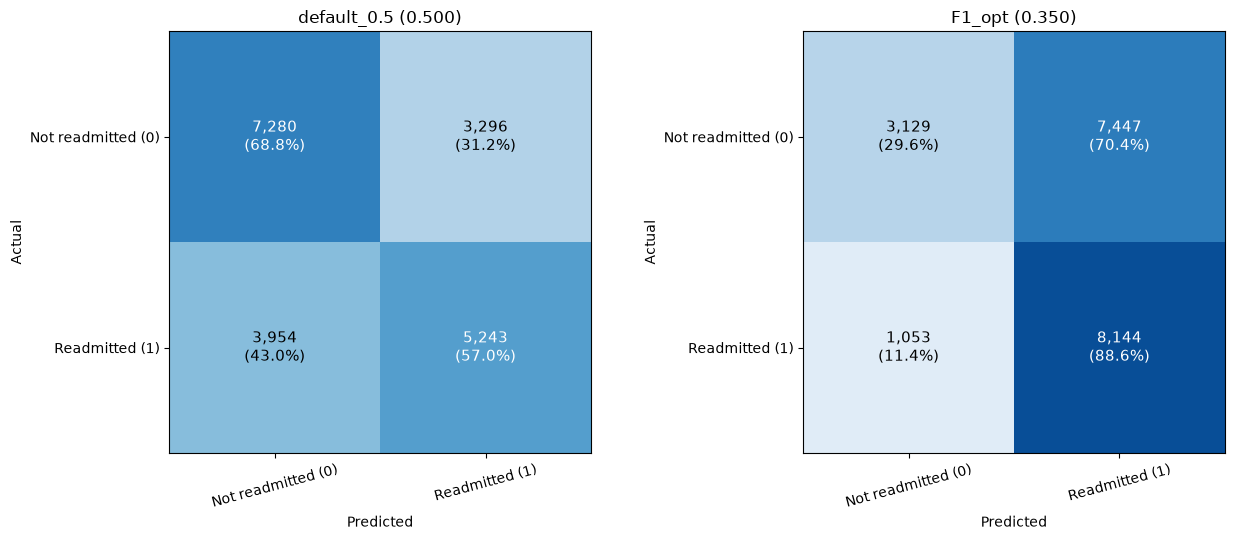

In [11]:
target_names = ["Not readmitted (0)", "Readmitted (1)"]
chosen = ["default_0.5", "F1_opt"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, name in zip(axes, chosen):
    t = thresholds[name]
    pred = (proba_test >= t).astype(int)
    print(f"\n{'='*55}\n{name} (threshold={t:.3f})\n{'='*55}")
    print(classification_report(y_test, pred, target_names=target_names, digits=4))
    cm = confusion_matrix(y_test, pred)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(target_names, rotation=15); ax.set_yticklabels(target_names)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"{name} ({t:.3f})")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cmn[i, j]*100:.1f}%)", ha="center", va="center",
                    color="white" if cmn[i, j] > 0.5 else "black", fontsize=11)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/confusion_matrix.png", dpi=150); plt.show()

## 9. Fairness ตามกลุ่มอายุ / เพศ / เชื้อชาติ

ใช้ threshold-free metric (ROC-AUC, PR-AUC) เป็นหลัก เพราะ base rate แต่ละกลุ่มต่างกัน — ดูว่า gap ของกลุ่มอายุมากที่เจอใน label เดิม (~0.56 vs ~0.70) ยังอยู่หรือไม่

In [12]:
def subgroup_report(group_values, group_name, min_n=30):
    out = []
    for g in sorted(group_values.unique()):
        m = (group_values == g).values
        yt, yp = y_test.values[m], proba_test[m]
        if m.sum() < min_n or len(np.unique(yt)) < 2:
            continue
        out.append({"group": g, "n": int(m.sum()), "base_rate": round(yt.mean(), 4),
                    "PR_AUC": round(average_precision_score(yt, yp), 4),
                    "ROC_AUC": round(roc_auc_score(yt, yp), 4)})
    res = pd.DataFrame(out)
    print(f"\n--- by {group_name} ---\n{res.to_string(index=False)}")
    return res

fairness = {c: subgroup_report(demo_test[c], c) for c in ["age", "gender", "race"]}


--- by age ---
   group    n  base_rate  PR_AUC  ROC_AUC
 [10-20)  137     0.3723  0.5896   0.6880
 [20-30)  369     0.4878  0.7863   0.8037
 [30-40)  757     0.4267  0.7385   0.7922
 [40-50) 1909     0.4301  0.6279   0.6942
 [50-60) 3467     0.4364  0.6497   0.6999
 [60-70) 4356     0.4628  0.6343   0.6776
 [70-80) 4921     0.4840  0.6182   0.6534
 [80-90) 3284     0.5088  0.6072   0.6297
[90-100)  547     0.4278  0.5208   0.5997

--- by gender ---
 group     n  base_rate  PR_AUC  ROC_AUC
Female 10726     0.4726  0.6381   0.6811
  Male  9047     0.4563  0.6343   0.6790

--- by race ---
          group     n  base_rate  PR_AUC  ROC_AUC
AfricanAmerican  3697     0.4585  0.6320   0.6817
          Asian   116     0.3448  0.4698   0.6681
      Caucasian 14813     0.4738  0.6398   0.6756
       Hispanic   398     0.4020  0.6523   0.7372
        Missing   447     0.3535  0.6067   0.7154
          Other   302     0.4139  0.5931   0.6909


## 10. บันทึกผล

In [13]:
pd.DataFrame({
    "encounter_id": meta["encounter_id"].values[test_idx],
    "patient_nbr": groups[test_idx],
    "y_true": y_test.values,
    "proba_calibrated": proba_test,
}).to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)

threshold_table.to_csv(f"{OUT_DIR}/threshold_table.csv", index=False)
for c, r in fairness.items():
    r.to_csv(f"{OUT_DIR}/fairness_{c}.csv", index=False)
with open(f"{OUT_DIR}/metrics.json", "w") as f:
    json.dump(results, f, indent=2)

joblib.dump({
    "label_mode": LABEL_MODE,
    "stacking_model": stacking_model,
    "isotonic_calibrator": iso,
    "thresholds": thresholds,
    "label_encoders": label_encoders,
    "feature_names": X_fit.columns.tolist(),
    "results": results,
}, f"{MODEL_DIR}/model_11_{LABEL_MODE}.pkl")
print(f"Saved → {OUT_DIR}/ และ {MODEL_DIR}/model_11_{LABEL_MODE}.pkl")

Saved → ../outputs/11_any/ และ ../models/model_11_any.pkl


## 11. ตารางเปรียบเทียบ label สองแบบ (สำหรับเปเปอร์)

รัน notebook นี้สองรอบ: `LABEL_MODE = "any"` และ `"30d"` แล้วเซลล์นี้จะรวมผลให้ ใช้คอลัมน์ lift / skill score ในการเทียบ ไม่ใช่ PR-AUC ดิบ

In [14]:
rows = []
for mode in ["30d", "any"]:
    p = f"../outputs/11_{mode}/metrics.json"
    if os.path.exists(p):
        rows.append(json.load(open(p)))
if len(rows) == 2:
    print(pd.DataFrame(rows).set_index("label_mode").T.to_string())
else:
    print("ยังรันไม่ครบทั้งสองแบบ — เปลี่ยน LABEL_MODE แล้วรันใหม่")

ยังรันไม่ครบทั้งสองแบบ — เปลี่ยน LABEL_MODE แล้วรันใหม่
